In [1]:
import numpy as np 
import netCDF4 as nc 
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt
import matplotlib.pyplot as plt 
import geopandas as gpd
import matplotlib.ticker as mticker
from shapely.geometry import Point
from rasterio.features import geometry_mask
from affine import Affine
import xarray as xr 
import pandas as pd 
import json

### GFEI

In [2]:
bound_permian = gpd.read_file(r"shapefiles/Boundary_PermianBasin_StudyArea_NAD27.shp")
bound_state = gpd.read_file(r"shapefiles/Boundary_State_NAD27.shp")
bound_permian = bound_permian.drop(bound_permian.index[1])
bound_permian = bound_permian.to_crs("EPSG:4326")

In [3]:
geoms = bound_permian.to_crs("EPSG:4326")["geometry"].values

In [4]:
# GFEI v3.0 (2020) oil and gas sector files (Oil_All + Gas_All; IPCC 1B2). The comparison is restricted to the oil and gas
# sectors; the total-fuel-exploitation product (which also contains coal mining, 1B1) is no longer used.
from cs1_gfei import load_gfei, total_cv
G = load_gfei(".")
GFEI_lat, GFEI_lon = G["lat"], G["lon"]
GFEI_kg = G["kg"]                       # kg a-1 per 0.1 degree cell, oil + gas
print({k: v.shape for k, v in G.items() if hasattr(v, "shape")})


{'lat': (1800,), 'lon': (3600,), 'kg_oil': (1800, 3600), 'kg_gas': (1800, 3600), 'kg': (1800, 3600), 'rsd_oil': (1800, 3600), 'rsd_gas': (1800, 3600)}


In [5]:
# (variables, area and unit conversion are handled in cs1_gfei.load_gfei)


In [6]:
# (kg per cell already computed by cs1_gfei.load_gfei)


In [7]:
nrows, ncols = GFEI_kg.shape
west, east = GFEI_lon.min(), GFEI_lon.max()
south, north = GFEI_lat.min(), GFEI_lat.max()

xres = (east - west) / ncols
yres = (north - south) / nrows
transform = Affine.translation(west, south) * Affine.scale(xres, yres)

In [8]:
xres

np.float64(0.09997222222222221)

In [9]:
yres

np.float64(0.09994444444444445)

In [10]:
# Step 3: Create mask (True outside, False inside)
mask = geometry_mask(
    geometries=geoms,
    out_shape=GFEI_kg.shape,
    transform=transform,
    invert=True  # invert=True means: True where inside the polygon
)

In [11]:
# Relative standard deviation per cell. GFEI v3.0 provides no uncertainty layer, so the GFEI v1.0 (2016) per-sector
# files Oil_All_rsd and Gas_All_rsd are used. For the map, the emission-weighted rsd of the two sectors in each cell.
with np.errstate(invalid="ignore", divide="ignore"):
    unc = np.where(GFEI_kg > 0, (G["kg_oil"] * G["rsd_oil"] + G["kg_gas"] * G["rsd_gas"]) / GFEI_kg, np.nan)
unc_masked = np.where(mask, unc, np.nan)


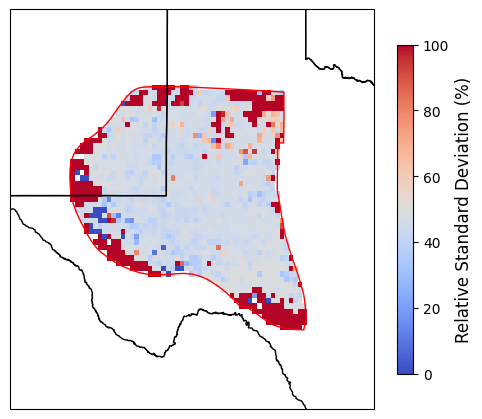

In [12]:
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={'projection': ccrs.PlateCarree()})
img = ax.imshow(
    unc_masked*100,
    extent=[west, east, south, north],
    origin='lower',
    transform=ccrs.PlateCarree(),
    cmap='coolwarm'
)

# Add boundary overlays
bound_permian.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1, transform=ccrs.PlateCarree())
bound_state.to_crs("EPSG:4326").plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1, transform=ccrs.PlateCarree())

# Colorbar and labels
cbar = plt.colorbar(img, ax=ax, orientation='vertical', shrink=0.7)
cbar.set_label("Relative Standard Deviation (%)", fontsize=12)

# Zoom in on Permian
ax.set_xlim(-105.5-1, -99.5+1)
ax.set_ylim(29-1, 34.5+1)

plt.tight_layout()

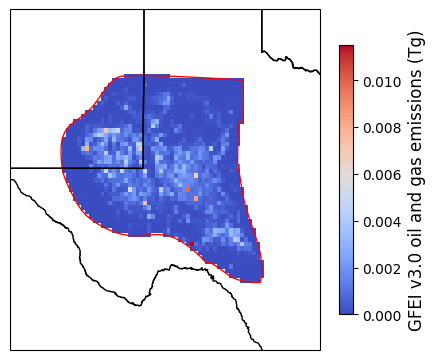

In [13]:
GFEI_masked = np.where(mask,GFEI_kg, np.nan)
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={'projection': ccrs.PlateCarree()})
img = ax.imshow(
    GFEI_masked*10**-9,
    extent=[west, east, south, north],
    origin='lower',
    transform=ccrs.PlateCarree(),
    cmap='coolwarm'
)

# Add boundary overlays
bound_permian.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1, transform=ccrs.PlateCarree())
bound_state.to_crs("EPSG:4326").plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1, transform=ccrs.PlateCarree())

# Colorbar and labels
cbar = plt.colorbar(img, ax=ax, orientation='vertical', shrink=0.7)
cbar.set_label("GFEI v3.0 oil and gas emissions (Tg)", fontsize=12)

# Zoom in on Permian
ax.set_xlim(-105.5-1, -99.5+1)
ax.set_ylim(29-1, 34.5+1)

plt.savefig("GFEI.png", dpi=600)

In [14]:
# ---- GFEI uncertainty: statistical interpretation and aggregation (reviewer comment 1) ----
# GFEI v3.0 ships no uncertainty layer; the per-cell relative standard deviations (rsd, "relative standard deviation for a
# normal pdf") of the GFEI v1.0 (2016) sector files Oil_All_rsd and Gas_All_rsd are applied to the v3.0 sector emissions.
# The cell errors are driven by shared activity-data and emission-factor errors, so they are treated as fully correlated
# across the study polygon and across the two sectors. Under full correlation the standard deviation of the regional total is
# the SUM of the per-cell, per-sector standard deviations, i.e. the relative standard deviation of the total is the
# EMISSION-WEIGHTED mean of the per-cell rsd:   CV_total = sum_i(E_oil,i rsd_oil,i + E_gas,i rsd_gas,i) / sum_i(E_i)
# Alternatives printed for comparison: sectors independent (cells correlated within each sector), all cells independent
# (quadrature; the lower bound), and the earlier root-mean-square / unweighted spatial mean of the cell values.
GFEI_masked = np.where(mask, GFEI_kg, np.nan)
Gsub = {k: G[k] for k in ("kg_oil", "kg_gas", "rsd_oil", "rsd_gas")}
cvs = total_cv(Gsub, mask)
gfei_rel_unc = float(cvs["fully_correlated"])   # adopted
cv_alternatives = {
    "emission-weighted mean rsd, both sectors (fully correlated; adopted)": gfei_rel_unc,
    "  oil sector alone / gas sector alone": (round(float(cvs["cv_oil"]), 3), round(float(cvs["cv_gas"]), 3)),
    "sectors independent, cells correlated within sector": float(cvs["sectors_independent"]),
    "all cells independent (quadrature)": float(cvs["cells_independent"]),
    "unweighted spatial mean of the per-cell rsd": float(np.nanmean(unc_masked)),
    "root-mean-square of the per-cell rsd (earliest notebook)": float(np.sqrt(np.nanmean(unc_masked ** 2))),
}
for k, v in cv_alternatives.items():
    print(f"{k:70s} {v}")


emission-weighted mean rsd, both sectors (fully correlated; adopted)   0.4576654553025779
  oil sector alone / gas sector alone                                  (0.463, 0.454)
sectors independent, cells correlated within sector                    0.32599444508793235
all cells independent (quadrature)                                     0.019173981919438827
unweighted spatial mean of the per-cell rsd                            0.5432397822362964
root-mean-square of the per-cell rsd (earliest notebook)               0.5847121068405199


### Event Estimation 

In [15]:
# Load sources 
features = [] 
with open("CM_sources.json", 'r') as f: 
    data = json.load(f)
    feats = data["features"]
    for feat in feats: 
        if feat not in features: 
            features.append(feat) 
cm_sources = pd.DataFrame(features)

sources = []
for _,row in cm_sources.iterrows():
    plume_ids = row.properties.get("plume_ids") 
    plume_2024 = False  
    for plume_id in plume_ids: 
        if "2024" in plume_id:
            plume_2024 = True
    if plume_2024: 
        sources.append({
            "source_name": row.id, 
            "source_lon": row.geometry.get("coordinates")[0],
            "source_lat": row.geometry.get("coordinates")[1],
            "plume_count":row.properties.get("plume_count"),
            "scene_count":len(row.properties.get("observation_scenes_names")),
            "scene_names": row.properties.get("observation_scenes_names"),
            "plume_ids": row.properties.get("plume_ids"),
            "persistence": row.properties.get("persistence"),
            "published_at_max": row.properties.get("published_at_max"),
            "published_at_min": row.properties.get("published_at_min"),
            "timestamp_max": row.properties.get("timestamp_max"),
            "timestamp_min": row.properties.get("timestamp_min"),
            "source_rate": row.properties.get("emission_auto"),
            "source_rate_unc": row.properties.get("emission_uncertainty_auto"),
        })
        
source_df = pd.DataFrame(sources)

In [16]:
tdf = pd.read_csv("total_emissions.csv")

In [17]:
tdf.head()

,Unnamed: 0,source,detection_dates,observation_dates,persistence,occupancy_mean,occupancy_q2.5,occupancy_q97.5,pre_emissions,pre_emissions_lower,pre_emissions_upper,ue_emissions,ue_emissions_lower,ue_emissions_upper,total_emissions,total_emissions_lower,total_emissions_upper
0,0,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,1.0,4.0,0.250000,0.216016,0.008245,0.641694,3.174087e+07,7.667496e+06,1.075182e+07,0.000000,0.000000,3.456283e+06,3.210406e+07,7.826267e+06,1.116927e+07
1,1,CH4_1B2_250m_-101.32793_32.36330?datetime=2024...,1.0,4.0,0.250000,0.216016,0.008245,0.641694,4.615870e+06,9.136439e+05,1.125160e+06,45067.351993,45067.351993,6.645499e+06,4.921678e+06,1.109164e+06,6.376660e+06
2,2,CH4_1B2_250m_-101.44280_31.39131?datetime=2024...,1.0,3.0,0.333333,0.263905,0.010532,0.741643,5.027893e+06,7.399084e+05,8.527543e+05,168493.799785,168493.799785,7.987182e+06,5.425597e+06,1.012763e+06,7.899744e+06
3,3,CH4_1B2_250m_-101.52275_32.51480?datetime=2024...,2.0,3.0,0.666667,0.502797,0.095433,0.923008,3.126428e+07,8.368539e+06,1.147092e+07,147433.602811,147433.602811,3.302131e+06,3.178463e+07,8.537615e+06,1.181889e+07
4,4,CH4_1B2_250m_-101.55170_32.28120?datetime=2024...,1.0,7.0,0.142857,0.139325,0.005079,0.446975,2.018401e+07,5.403356e+06,7.137117e+06,0.000000,0.000000,2.583304e+06,2.038330e+07,5.451325e+06,7.556101e+06


In [18]:
pre = []
pre_upper = []
pre_lower =  []
ue =  [] 
ue_upper = []
ue_lower =  []
for _,row in tdf.iterrows(): 
    pre.append(row.pre_emissions)
    pre_upper.append(row.pre_emissions_upper)
    pre_lower.append(row.pre_emissions_lower)
    ue.append(row.ue_emissions) 
    ue_upper.append(row.ue_emissions_upper)
    ue_lower.append(row.ue_emissions_lower)

In [19]:
# ---- Basin (cohort) total: the joint Monte Carlo ensemble computed in Case_study_No1.ipynb (cs1_joint_ensemble.py).
# In every iteration the plume quantification errors, the event rates, the bootstrap-refit UE distributions, the
# occupancy of each source and the UE draws are sampled first and PRE + UE are then summed over all sources. The
# central estimate and the 95% CI are the median and the 2.5th / 97.5th percentiles of that ensemble of totals.
# No component medians or bounds are summed and no bound is combined with an uncertainty magnitude in quadrature
# (the earlier root-mean-square combination of the PRE bound and the UE uncertainty has been removed).
# total_emissions.csv (per-source medians and one-sided deviations) is used only for the gridded map below.
basin_total_draws = np.load("cs1_basin_total_ensemble.npy")
eameet_median = np.median(basin_total_draws) / 1e9
eameet_lo = np.percentile(basin_total_draws, 2.5) / 1e9
eameet_hi = np.percentile(basin_total_draws, 97.5) / 1e9
print(f"Sum of per-source medians (shown for comparison only -- not the reported estimate): "
      f"{tdf.total_emissions.sum()*1e-9:.3f} Tg")
print(f"EAMEET v1.0 cohort total (joint ensemble, N={len(basin_total_draws)}): median={eameet_median:.3f} Tg, "
      f"95% CI [{eameet_lo:.3f}, {eameet_hi:.3f}] Tg")


Sum of per-source medians (shown for comparison only -- not the reported estimate): 1.577 Tg
EAMEET v1.0 cohort total (joint ensemble, N=10000): median=2.082 Tg, 95% CI [1.921, 2.285] Tg


In [20]:
latitudes = [] 
longitudes = [] 
for _,row in tdf.iterrows():
    source = row.source
    sdf = source_df[source_df.source_name == source].copy()
    lat = sdf.source_lat.iloc[0]
    lon = sdf.source_lon.iloc[0]
    latitudes.append(lat)
    longitudes.append(lon)
tdf["latitudes"] = latitudes
tdf["longitudes"] = longitudes

In [21]:
# our study region
north = 34.5 
south = 29 
west = -105.5 
east = -99.5 
lat_bins = np.arange(np.floor(south), np.ceil(north)+ 0.1, 0.1)
lon_bins = np.arange(np.floor(west), np.ceil(east)+ 0.1, 0.1)
lon_2d, lat_2d = np.meshgrid(lon_bins, lat_bins) # lat & lon

In [22]:
def find_indices (target_lon,target_lat,X,Y):
    '''
    target_lat: target latitude
    target_lon: target longitude 
    X: 2D longitude array (-180,180)   
    Y: 2D latitude array (90,-90)
    '''
    lat_diff = np.abs(Y - target_lat)
    lon_diff = np.abs(X - target_lon)
    total_diff = lat_diff + lon_diff
    ind_x, ind_y = np.unravel_index(np.argmin(total_diff), total_diff.shape)
    return ind_x, ind_y 

In [23]:
### Source Count
source_counts = np.zeros(np.shape(lon_2d))
for _,row in tdf.iterrows(): 
    x_ind,y_ind = find_indices(row.longitudes,row.latitudes,lon_2d,lat_2d)
    source_counts[x_ind,y_ind] += 1 

In [24]:
source_counts = np.where(source_counts == 0, np.nan, source_counts)

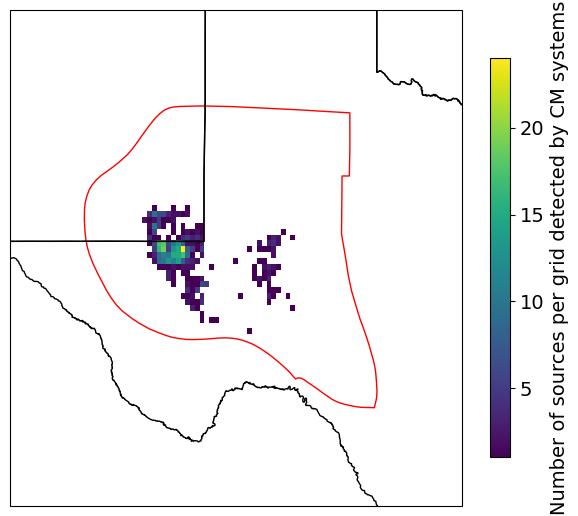

In [25]:
# Set up map projection
proj = ccrs.PlateCarree()

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'projection': proj})

# Plot the data using imshow
img = ax.imshow(
    source_counts,
    extent=[west, east, south, north],
    origin='lower',
    transform=proj,
    cmap='viridis'
)

bound_permian.plot(
    ax=ax,
    facecolor='none', 
    edgecolor='red',   
    linewidth=1,
    transform=proj  
)
bound_state.plot(
    ax=ax,
    facecolor='none',  
    edgecolor='black',  
    linewidth=1,
    transform=proj 
)

# Add colorbar
cbar = plt.colorbar(img, ax=ax, orientation='vertical', shrink=0.7)
cbar.set_label("Number of sources per grid detected by CM systems",fontsize=14)
cbar.ax.tick_params(labelsize=14)
ax.set_xlim(west-1, east+1)
ax.set_ylim(south-1, north+1)

plt.tight_layout()
plt.savefig("CM_source_counts.png", dpi=600)

In [26]:
emission_2d = np.zeros(np.shape(lon_2d))
for _,row in tdf.iterrows(): 
    x_ind,y_ind = find_indices(row.longitudes,row.latitudes,lon_2d,lat_2d)
    emission_2d[x_ind,y_ind] += row.total_emissions   # per-source median, for the map only


In [27]:
emission_2d = np.where(emission_2d== 0, np.nan, emission_2d)

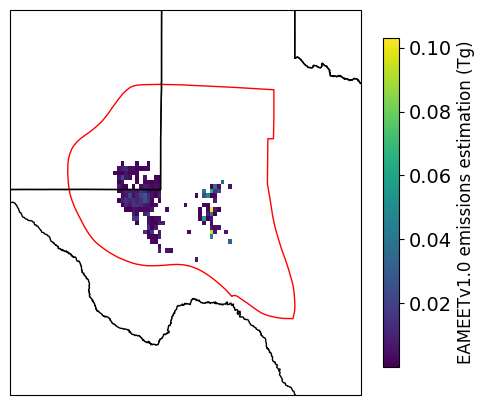

In [28]:
# Set up map projection
proj = ccrs.PlateCarree()

fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={'projection': proj})

# Plot the data using imshow
img = ax.imshow(
    emission_2d*10**-9,
    extent=[west, east, south, north],
    origin='lower',
    transform=proj,
    cmap='viridis'
)

bound_permian.plot(
    ax=ax,
    facecolor='none', 
    edgecolor='red',   
    linewidth=1,
    transform=proj  
)
bound_state.plot(
    ax=ax,
    facecolor='none',  
    edgecolor='black',  
    linewidth=1,
    transform=proj 
)

# Add colorbar
cbar = plt.colorbar(img, ax=ax, orientation='vertical', shrink=0.7)
cbar.set_label("EAMEETv1.0 emissions estimation (Tg)", fontsize=12)
cbar.ax.tick_params(labelsize=14)
# Zoom in on Permian
ax.set_xlim(-105.5-1, -99.5+1)
ax.set_ylim(29-1, 34.5+1)
plt.tight_layout()
plt.savefig("EAMEET_emissions_estimation.png", dpi=600)

### compare emissions from events and GFEI

In [29]:
# GFEI v3.0 oil and gas total over the study polygon with its 95% interval. gfei_rel_unc is the emission-weighted mean of the
# GFEI v1.0 per-cell, per-sector relative standard deviations (fully correlated errors; see the aggregation cell above). GFEI describes
# the rsd as the relative standard deviation of a normal pdf; a normal interval with this CV would reach below zero, so
# the regional total is modelled as LOGNORMAL with the same coefficient of variation, consistent with the right-skewed
# rate and duration distributions used elsewhere in this study, and the GFEI total is its median (the same
# median-as-central-estimate convention as for the EAMEET ensemble).
from scipy import stats

gfei_total = np.nansum(GFEI_masked)
sigma = np.sqrt(np.log(1 + gfei_rel_unc ** 2))
mu = np.log(gfei_total)  # lognormal median = gfei_total
gfei_lo = np.exp(mu + sigma * stats.norm.ppf(0.025))
gfei_hi = np.exp(mu + sigma * stats.norm.ppf(0.975))

print(f"GFEI v3.0 oil and gas total over the study polygon (median): {gfei_total/1e9:.3f} Tg, relative standard deviation "
      f"(emission-weighted mean rsd, GFEI v1.0): {gfei_rel_unc:.3f}")
print(f"Lognormal 95% CI (median-matched, same CV): [{gfei_lo/1e9:.3f}, {gfei_hi/1e9:.3f}] Tg")
print(f"EAMEET / GFEI (full polygon): {eameet_median / (gfei_total/1e9):.2f}")


GFEI v3.0 oil and gas total over the study polygon (median): 0.953 Tg, relative standard deviation (emission-weighted mean rsd, GFEI v1.0): 0.458
Lognormal 95% CI (median-matched, same CV): [0.405, 2.239] Tg
EAMEET / GFEI (full polygon): 2.19


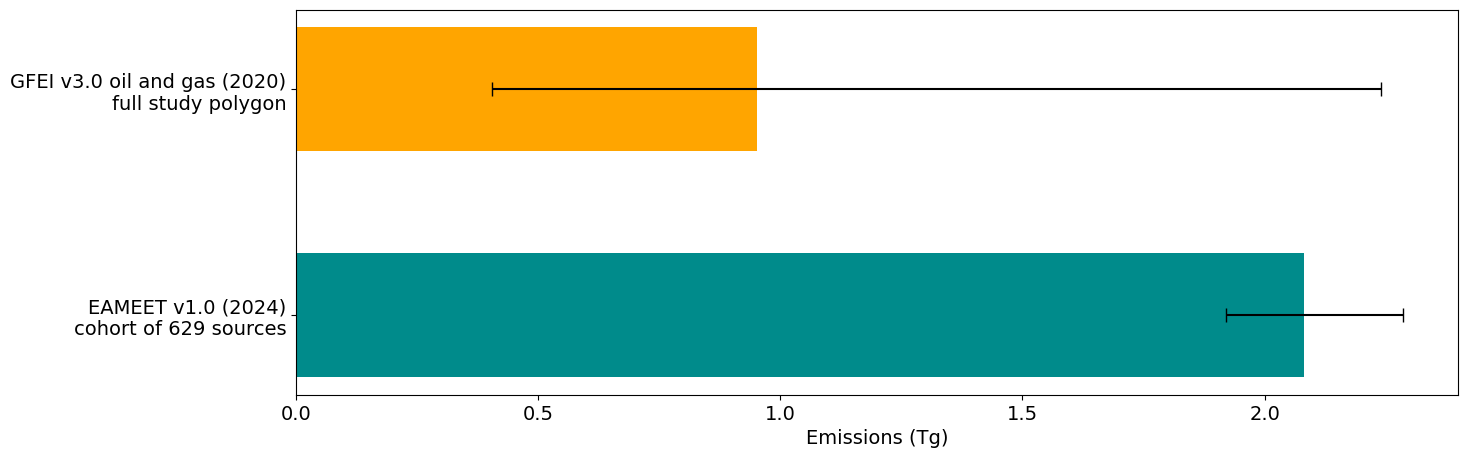

In [30]:
plt.figure(figsize=(15, 5))
categories = ['EAMEET v1.0 (2024)\ncohort of 629 sources', "GFEI v3.0 oil and gas (2020)\nfull study polygon"]
values = [eameet_median, gfei_total / 1e9]
errors = [[eameet_median - eameet_lo, gfei_total / 1e9 - gfei_lo / 1e9],
          [eameet_hi - eameet_median, gfei_hi / 1e9 - gfei_total / 1e9]]
bar_width = 0.55
colors = ['darkcyan', 'orange']
index = np.arange(len(categories))
plt.barh(index, values, xerr=errors, height=bar_width, color=colors, capsize=5)
#plt.ylabel('Categories')
plt.xlabel('Emissions (Tg)', fontsize=14)
plt.yticks(index, categories, fontsize=14)
plt.xticks(fontsize=14)
plt.savefig("CM_vs_GFEI.png", dpi=300)